# The scorecard idea: weight of evidence, information value and points

**Question:** Can a credit officer read the default risk of a card from a printed table of points, and how much of the ranking power of the model behind the table survives the rounding to whole points?

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01 (getting started)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- say what the weight of evidence (WoE) and the information value (IV) of a binned variable measure, and compute both from the counts of a bin;
- explain how a logistic model on WoE becomes a table of points, and what the points to double the odds (PDO) mean;
- rebuild the PD of a card from its integer score alone and see what the rounding of the points costs;
- read the discrimination and the grade table of the scorecard on 9,000 held-out cards with the engine's AUC, KS and grade tests.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation.calibration import pd_chi2_grades, pd_jeffreys_grades
from riskvalidation.validation.discrimination import auc_with_variance, cap_accuracy_ratio, disc_auc, disc_ks

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C01, the PD of retail credit cards, as Contraste commits it. The 30,000 cards come from the UCI Taiwan credit-card file (Yeh, 2009; owner: UCI Machine Learning Repository; CC BY 4.0, licence class `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). The pipeline split them once with a fixed seed: 16,800 cards to fit the scorecard, 4,200 to calibrate the challengers and a locked holdout of 9,000 cards that no fit has seen. Two committed files hold what this notebook needs, so it fits nothing and needs no raw data:

- `data/derived/C01/models-taiwan.json`: the fitted scorecard (rung P1): coefficients, information values, scale and the table of points with the counts of every bin on the 16,800 training cards. Owner: this repository.
- `data/derived/C01/holdout.json`: the scorecard on the holdout: a sample of 50 cards with raw inputs, points, score and PD, the CAP curve and the 12-grade table of the 9,000 cards, and the committed test rows.

The next cell loads both files and prints the size of the scorecard.

In [2]:
# Load the two committed files of case C01 (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
sample = holdout["outputs"]["sample"]
policy = rv.default_policy()
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
print("training cards:", models["fit"]["train_rows"], "| variables kept:", len(card["features"]))
print("rows of the table:", len(table))
print("baked by riskvalidation", models["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

training cards: 16800 | variables kept: 13
rows of the table: 95
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: a variable in bins, and the weight of evidence of each bin

A scorecard never uses a raw variable. It cuts each one into a few ordered **bins**, chosen so that the default rate rises (or falls) steadily from one bin to the next and no bin holds fewer than 5% of the cards, and it works with the bin a card falls in. A bin is a row of a printed table: a credit officer can read it and an auditor can check it. The variable with the strongest signal is `PAY_0`, the repayment status of the latest month (-1 paid duly, 1 one month late, 2 two months late, and so on). The next cell takes its bins from the points table of the fitted scorecard and computes the weight of evidence of each from the counts of defaulters and non-defaulters. With $r^{NE}_i / r^{NE}_T$ the share of all non-events that fall in bin $i$ and $r^{E}_i / r^{E}_T$ the share of all events, the weight of evidence and the information value are (Navas-Palencia, 2020, section 2.1)

$$\mathrm{WoE}_i = \ln\!\left(\frac{r_i^{NE} / r_T^{NE}}{r_i^{E} / r_T^{E}}\right), \qquad \mathrm{IV} = \sum_i \left(\frac{r_i^{NE}}{r_T^{NE}} - \frac{r_i^{E}}{r_T^{E}}\right)\mathrm{WoE}_i .$$

A higher WoE means a lower risk, because the bin holds more good cards than bad ones. The information value adds up how far apart the two shares are, bin by bin; an IV of 0 means the variable does not separate defaulters from the rest at all. The cell prints the IV and draws the cards and the default rate of each bin beside its WoE.

IV of PAY_0 from the counts: 0.8862 | WoE of the bins: [ 0.637  0.581 -0.585 -2.09 ]


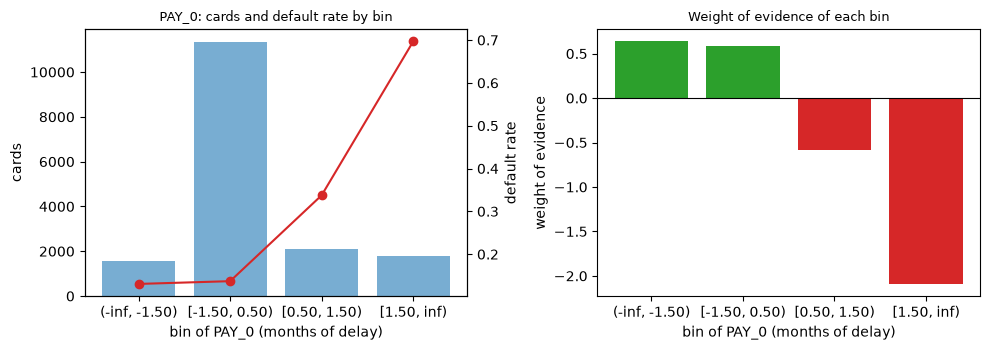

In [3]:
# WoE and IV of the PAY_0 bins from their counts, beside the cards and default rate of each bin
pay0 = [r for r in table if r["feature"] == "PAY_0" and r["count"] > 0]
bins_ = [r["bin"] for r in pay0]
events = np.array([r["events"] for r in pay0], dtype=float)
non_events = np.array([r["count"] - r["events"] for r in pay0], dtype=float)
share_ne, share_e = non_events / non_events.sum(), events / events.sum()
woe = np.log(share_ne / share_e)
iv_bins = (share_ne - share_e) * woe
print("IV of PAY_0 from the counts:", round(float(iv_bins.sum()), 4), "|", "WoE of the bins:", np.round(woe, 3))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(bins_, events + non_events, color="tab:blue", alpha=0.6)
left.set_xlabel("bin of PAY_0 (months of delay)")
left.set_ylabel("cards")
rate_axis = left.twinx()
rate_axis.plot(bins_, events / (events + non_events), color="tab:red", marker="o")
rate_axis.set_ylabel("default rate")
left.set_title("PAY_0: cards and default rate by bin", fontsize=9)
right.bar(bins_, woe, color=np.where(woe > 0, "tab:green", "tab:red"))
right.axhline(0, color="black", linewidth=0.8)
right.set_xlabel("bin of PAY_0 (months of delay)")
right.set_ylabel("weight of evidence")
right.set_title("Weight of evidence of each bin", fontsize=9)
fig.tight_layout()
plt.show()

Read the left panel first: the cards pile up in the second bin (those who paid duly or revolved), and the default rate jumps from about 13% in the first two bins to about 70% in the last, the cards two or more months late. The right panel turns those rates into evidence. The two best bins have a positive WoE and the last has a WoE near -2, so a card in it carries about $e^{2}$, roughly seven times, more evidence of default than the average card. The IV of 0.886 is large: conventionally a variable above 0.5 is considered suspiciously strong, and here it is the repayment history, which is a consequence of default as much as a cause of it. What the figure does not show is whether the bins were chosen on the right cards. They were fitted on the 16,800 training cards only, which is the subject of notebook 02.

### Step 2: which variables are worth keeping

The same IV can be read for every variable. The fit keeps a variable only if its IV reaches 0.02, a screening convention attributed to Siddiqi (2017) whose book page the research could not verify; it is a rule of thumb, not a theorem. The next cell draws the IV of the 20 variables of the file from the scorecard's own record, blue for the 13 kept and grey for the 7 dropped, against the threshold.

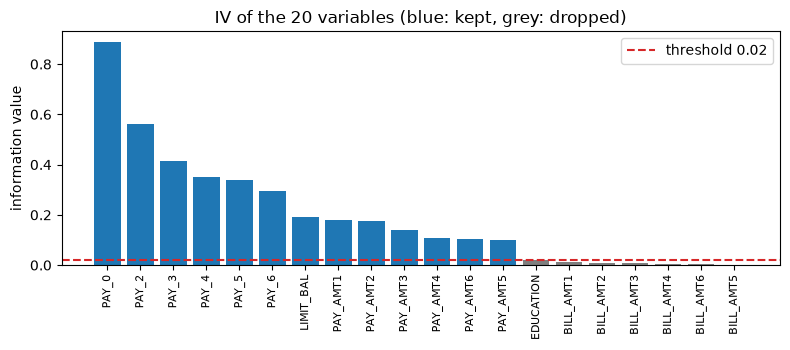

variables kept by the 0.02 threshold: 13 / 20
PAY_0: 0.8862 | EDUCATION: 0.0189


In [4]:
# Draw the information value of every variable against the 0.02 screening threshold
ranked = sorted(card["iv"].items(), key=lambda item: -item[1])
names = [n for n, _ in ranked]
colors = ["tab:blue" if n in card["features"] else "tab:gray" for n in names]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(names, [v for _, v in ranked], color=colors)
ax.axhline(0.02, color="tab:red", linestyle="--", label="threshold 0.02")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.set_ylabel("information value")
ax.set_title("IV of the 20 variables (blue: kept, grey: dropped)")
ax.legend()
fig.tight_layout()
plt.show()
print("variables kept by the 0.02 threshold:", len(card["features"]), "/", len(ranked))
print("PAY_0:", round(card["iv"]["PAY_0"], 4), "| EDUCATION:", round(card["iv"]["EDUCATION"], 4))

The six repayment-status variables dominate, followed by the credit limit and the six payment amounts. The six bill amounts and the education level sit below the line: once the repayment status is known they add almost nothing, and `EDUCATION` falls just under the threshold. The picture also says something the threshold hides: the 13 kept variables are not 13 independent pieces of evidence, since `PAY_0` to `PAY_6` describe the same behaviour in consecutive months. That is why the logistic step of the next section matters, and why every coefficient has to be checked for its sign.

### Step 3: from evidence to points

A logistic model on the WoE of the kept variables gives the log-odds of default $\eta = \beta_0 + \sum_j \beta_j\,\mathrm{WoE}_j$. Because a higher WoE means a lower risk, every coefficient of a sound scorecard is negative. A desk does not work with log-odds, so the model is turned into a score that is linear in the log-odds of being good and is fixed by three numbers: the reference score (600), the reference odds (50 to 1) and the points to double the odds, PDO = 20 (Siddiqi, 2017; the formula as ING's open `skorecard` implements it):

$$\mathrm{Factor} = \frac{\mathrm{PDO}}{\ln 2}, \quad \mathrm{Offset} = \mathrm{Score}_{ref} - \mathrm{Factor}\cdot\ln(\mathrm{odds}_{ref}), \quad \mathrm{Points}_{j,b} = \frac{\mathrm{Offset}}{k} - \left(\beta_j\,\mathrm{WoE}_{j,b} + \frac{\beta_0}{k}\right)\mathrm{Factor}.$$

The offset and the intercept are shared out evenly among the $k$ kept variables so that the score is a plain sum of per-bin points, and the points are then rounded to integers because a scorecard is a printed table. The next cell computes the Factor and the Offset from the three scale numbers, the points of the `PAY_0` bins from their WoE with the committed coefficient, and draws the points of two variables.

Factor and Offset: 28.8539 487.1229
PAY_0 points, unrounded then rounded: [53.91 52.72 27.7  -4.6 ] [54 53 28 -5]


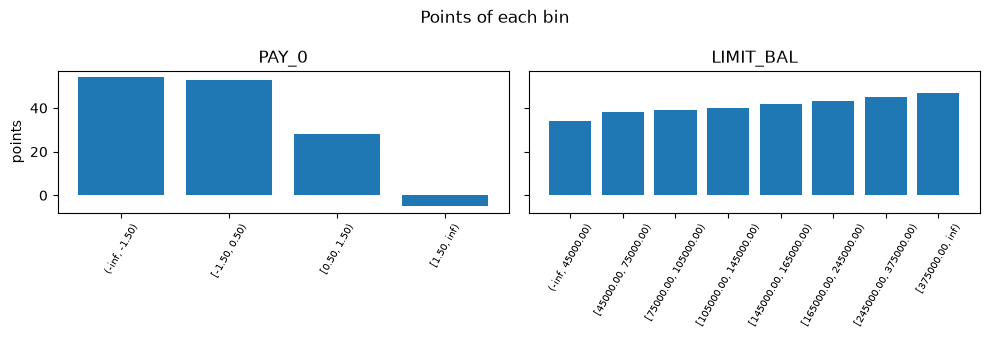

In [5]:
# Factor and Offset from the three scale numbers, the points of the PAY_0 bins, and the points of two variables
pdo, odds_ref, score_ref = 20.0, 50.0, 600.0
factor = pdo / np.log(2.0)
offset = score_ref - factor * np.log(odds_ref)
k, beta_0 = len(card["features"]), card["intercept"]
points_raw = offset / k - (card["coefficients"]["PAY_0"] * woe + beta_0 / k) * factor
print("Factor and Offset:", round(float(factor), 4), round(float(offset), 4))
print("PAY_0 points, unrounded then rounded:", np.round(points_raw, 2), np.round(points_raw).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, name in zip(axes, ("PAY_0", "LIMIT_BAL")):
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    ax.bar([r["bin"] for r in rows], [r["points"] for r in rows], color="tab:blue")
    ax.tick_params(axis="x", labelrotation=60, labelsize=7)
    ax.set_title(name)
axes[0].set_ylabel("points")
fig.suptitle("Points of each bin")
fig.tight_layout()
plt.show()

The scale numbers come out as Factor 28.85 and Offset 487.12, and the unrounded points of the `PAY_0` bins (about 54, 53, 28 and -5) round to the integers of the printed table. The figure makes the weight of each variable concrete: the bins of `PAY_0` are spread over almost 60 points, from -5 for a card two or more months late to 54 for a card that paid duly, while the bins of `LIMIT_BAL` are spread over 14 points. A card's score is the sum over 13 variables, so a single late payment status can move it by more than all the credit-limit bins together. What the figure does not show is the cost of rounding, which the next steps measure.

### Step 4: the score is a sum, and the PD can be read back from it

To score a card one finds its bin in each variable and adds the points. The holdout file keeps 50 cards with their 13 point columns, their score and the PD of the unrounded model. Because the score is $\mathrm{Offset} - \mathrm{Factor}\,\eta$, the PD can be rebuilt from the integer score alone: $\eta = (\mathrm{Offset} - \mathrm{Score})/\mathrm{Factor}$ and $\mathrm{PD} = 1/(1 + e^{-\eta})$. The PD of the model and the PD from the score differ only by the rounding of the points, and the PDO property says that 20 more points must halve the odds of default. The next cell sums the points of the 50 cards, rebuilds the PD, checks the doubling at scores 560 and 580 and draws the two PDs against each other.

largest PD gap on 50 cards: 0.0084
ratio of the odds of default at score 560 and 580: 2.0


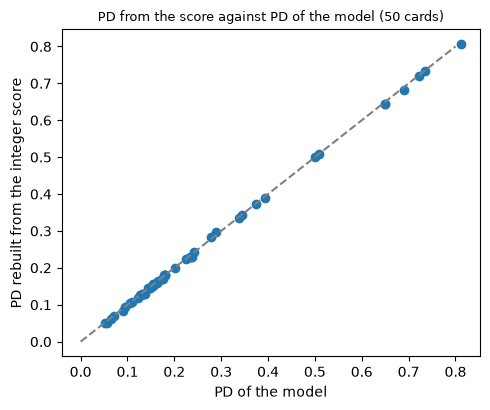

In [6]:
# Sum the points of the 50 sample cards, rebuild the PD from the integer score and check the doubling of the odds
y50 = np.array(sample["targets"])
score50 = np.array(sample["scorecard_points"]).sum(axis=1)
pd_model = np.array(sample["scorecard_pd"])
pd_points = 1.0 / (1.0 + np.exp(-(offset - score50) / factor))
print("largest PD gap on 50 cards:", round(float(np.abs(pd_points - pd_model).max()), 4))
two = 1.0 / (1.0 + np.exp(-(offset - np.array([560.0, 580.0])) / factor))
odds_pair = two / (1.0 - two)
print("ratio of the odds of default at score 560 and 580:", round(float(odds_pair[0] / odds_pair[1]), 3))
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(pd_model, pd_points, color="tab:blue")
ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--")
ax.set_xlabel("PD of the model")
ax.set_ylabel("PD rebuilt from the integer score")
ax.set_title("PD from the score against PD of the model (50 cards)", fontsize=9)
fig.tight_layout()
plt.show()

The 50 points sit on the diagonal, at most 0.008 away from it: rounding every one of 13 point columns to whole numbers moves a card's PD by less than a percentage point, and the ratio of the odds of default at 560 and 580 points is exactly 2, which is the meaning of PDO = 20. The figure shows the size of the distortion but not its direction for the ranking, and the ranking is what a scorecard is judged on first.

### Step 5: does the table keep the ranking? The engine's AUC and KS

The engine's `disc_auc` takes one risk value per card (higher is riskier) and the 0/1 outcome and returns the area under the ROC curve, the probability that a defaulter is ranked riskier than a non-defaulter, with its standard error (Hanley and McNeil, 1982; ECB, 2019, Annex 1, section 3.1). `disc_ks` returns the largest gap between the score distributions of defaulters and non-defaulters, and `auc_with_variance` returns the AUC with its variance and the counts of defaulters and non-defaulters. The next cell calls them on the 50 cards twice, with the PD of the model and with the PD rebuilt from the integer points, to see whether the rounding changes the ranking.

In [7]:
# The engine on the 50 cards: AUC, KS and interval of the model PD, and AUC of the PD from the points
auc_m = disc_auc(pd_model, y50, policy=policy, model_id="P1-scorecard")
auc_p = disc_auc(pd_points, y50, policy=policy, model_id="P1-scorecard")
ks_m = disc_ks(pd_model, y50, policy=policy, model_id="P1-scorecard")
auc_v, variance, n_def, n_good = auc_with_variance(pd_model, y50)
half = 1.96 * variance ** 0.5
print("AUC of the model PD, 50 cards:", round(auc_m.metric, 4))
print("95% interval of the first:", round(auc_v - half, 3), "-", round(auc_v + half, 3))
print("AUC of the PD rebuilt from the points, 50 cards:", round(auc_p.metric, 4))
print("KS of the model PD, 50 cards:", round(ks_m.metric, 4))

AUC of the model PD, 50 cards: 0.7752
95% interval of the first: 0.646 - 0.904
AUC of the PD rebuilt from the points, 50 cards: 0.7781
KS of the model PD, 50 cards: 0.5048


The AUC of the model PD is 0.7752 and that of the PD rebuilt from the integer points is 0.7781: the rounding did not hurt the ranking on these cards, it even moved the AUC up by 0.003, which is noise at this size. The interval of the first, from 0.65 to 0.90, is the more important number. With 15 defaulters among 50 cards nothing about the quality of the scorecard can be said, which is why the next step moves to the 9,000 held-out cards.

### Step 6: ranking on 9,000 held-out cards

The 9,000 cards themselves are not in the repository, but the holdout file commits the CAP curve of the scorecard: the cumulative share of defaulters caught as the population is cut at 1% steps from the riskiest card down. Each of the 100 slices holds 90 cards, and the share of defaulters it holds is the step of the curve. The next cell rebuilds from those steps a vector of 9,000 risk values and outcomes, giving every card of a slice the same value and the slices a decreasing order, and hands it to the engine. The within-slice order is lost, so the cards of a slice count as ties and the AUC is a slight under-estimate of the true one; the committed AUC of the same cards, computed by the pipeline on the cards themselves, is printed beside it.

AUC on 9000 cards, engine on 1% slices: 0.7586
AUC committed for the same cards: 0.7587
KS on 9000 cards: 0.3956
accuracy ratio on 9000 cards: 0.5173


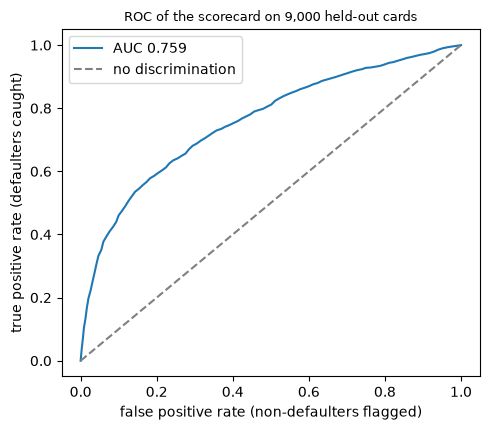

In [8]:
# Rebuild 9000 cards from the CAP steps (100 slices of 90 cards) and run the engine on them
cap = holdout["outputs"]["rungs"]["P1-scorecard"]["cap"]
n_cards, n_defaults = holdout["outputs"]["n"], holdout["outputs"]["defaults"]
defaults_per_slice = np.rint(np.diff(np.array(cap["defaults"])) * n_defaults).astype(int)
cards_per_slice = n_cards // len(defaults_per_slice)
risk9k = np.repeat(np.arange(len(defaults_per_slice), 0, -1), cards_per_slice)
flags = np.concatenate([np.r_[np.ones(d), np.zeros(cards_per_slice - d)] for d in defaults_per_slice])
auc9k = disc_auc(risk9k, flags, policy=policy, model_id="P1-scorecard")
ks9k = disc_ks(risk9k, flags, policy=policy, model_id="P1-scorecard")
committed_auc = next(t for t in holdout["tests"] if t["test_id"] == "disc.auc" and t["model_id"] == "P1-scorecard")
print("AUC on 9000 cards, engine on 1% slices:", round(auc9k.metric, 4))
print("AUC committed for the same cards:", round(committed_auc["metric"], 4))
print("KS on 9000 cards:", round(ks9k.metric, 4))
print("accuracy ratio on 9000 cards:", round(cap_accuracy_ratio(risk9k, flags), 4))
roc = holdout["outputs"]["rungs"]["P1-scorecard"]["roc"]
fig, ax = plt.subplots(figsize=(5, 4.4))
ax.plot(roc["fpr"], roc["tpr"], color="tab:blue", label=f"AUC {auc9k.metric:.3f}")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="no discrimination")
ax.set_xlabel("false positive rate (non-defaulters flagged)")
ax.set_ylabel("true positive rate (defaulters caught)")
ax.set_title("ROC of the scorecard on 9,000 held-out cards", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

The engine gives an AUC of 0.7586 on the rebuilt 9,000 cards against the committed 0.7587, so the loss from treating the 90 cards of a slice as ties is two ten-thousandths. A KS of 0.3956 and an accuracy ratio of 0.52 (twice the AUC minus one) say the same thing in other units: the scorecard separates defaulters from the rest clearly, though far from perfectly. The ROC curve shows where the separation comes from. It climbs steeply at the left, where a few percent of the non-defaulters flagged already catch a fifth of the defaulters, and flattens at the right. The curve says nothing about whether the PD is the right size, only about the order.

### Step 7: the grades of the master scale and their calibration

A bank sorts its cards into **grades** of equal meaning, here the 12 grades of the master scale with upper bounds $1\% \times 1.5^{k}$. For each grade the holdout file commits the cards, the defaults and the mean PD, so the engine can ask whether the defaults the grade shows are compatible with its PD. `pd_jeffreys_grades` runs the one-sided Jeffreys test (Brown, Cai and DasGupta, 2001) grade by grade, and `pd_chi2_grades` asks the question for all grades at once with a chi-square statistic (BCBS, 2005). The next cell runs both on the eight grades that hold cards and draws the mean PD of each grade next to its observed default rate.

chi-square over grades, p: 0.0264 amber
grades with p below 0.05 in the Jeffreys test: ['G08']


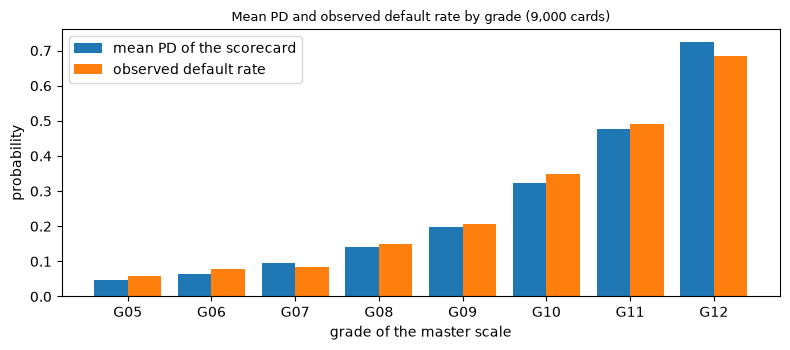

In [9]:
# The engine's Jeffreys test per grade and chi-square over grades, and the mean PD against the observed rate by grade
grades = [g for g in holdout["outputs"]["rungs"]["P1-scorecard"]["grades"] if g["n"] > 0]
n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
names_g = [g["grade"] for g in grades]
per_grade = pd_jeffreys_grades(n_g, d_g, pd_g, grades=names_g, policy=policy, model_id="P1-scorecard")
chi = pd_chi2_grades(n_g, d_g, pd_g, policy=policy, model_id="P1-scorecard", segment="portfolio")
flagged = [r.segment for r in per_grade if r.p_value < 0.05]
print("chi-square over grades, p:", round(chi.p_value, 4), LIGHT[chi.light.value])
print("grades with p below 0.05 in the Jeffreys test:", flagged)
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, pd_g, width=0.4, label="mean PD of the scorecard")
ax.bar(x + 0.2, [g["dr"] for g in grades], width=0.4, label="observed default rate")
ax.set_xticks(x, [g["grade"] for g in grades])
ax.set_xlabel("grade of the master scale")
ax.set_ylabel("probability")
ax.set_title("Mean PD and observed default rate by grade (9,000 cards)", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

The bars of the two series rise together from grade G05 to G12, which is what a master scale is for, and they are close: the observed rate sits slightly above the mean PD in the middle grades and below it in the riskiest grade. The chi-square over the grades has a p-value of 0.026, an amber light, and the Jeffreys test flags only grade G08, the largest one, with 3,101 cards. So the scorecard is a little too optimistic in the middle of the scale, a modest finding that the calibration tests of notebook 03 follow up. It would take a validator to call it a defect; for this notebook it is a measurement.

## Results

**Answer:** Yes: a printed table of points keeps almost all the ranking power of the model it comes from. The `PAY_0` variable alone carries an information value of 0.8862, and 13 of the 20 variables reach the 0.02 threshold. The Factor is 28.8539 and the Offset 487.1229, so a score is a plain sum of 13 integer points. Rounding the points moves the PD of a card by at most 0.0084 and the ratio of the odds of default 20 points apart is exactly 2. On 50 cards the AUC is 0.7752 with the model PD and 0.7781 with the PD rebuilt from the points, so the rounding costs nothing visible; the engine, run on 9,000 cards rebuilt from the CAP steps, gives an AUC of 0.7586 against the committed 0.7587, a KS of 0.3956 and an accuracy ratio of 0.517. By grade, the chi-square p-value is 0.0264 (amber) and only one grade of eight is flagged by the Jeffreys test.

What this notebook does not show: how the bins and the coefficients are fitted on the training cards only (notebook 02), how the scorecard compares with simpler and richer models and holds under a drift (notebook 03), whether it survives a change of period (notebooks 04 and 07) or beats the current challengers (notebook 06). The 50-card sample is far too small to judge quality, and the rebuilt 9,000 cards are the committed CAP curve, not the cards themselves.

## Summary

- The weight of evidence compares the share of non-defaulters and of defaulters in a bin, and the information value adds the difference over the bins; `PAY_0` reaches 0.886 and 13 of 20 variables pass the 0.02 screen.
- A logistic model on the WoE has negative coefficients when it is sound; its intercept and coefficients are shared out per variable into a table of points on a scale fixed by a reference score, reference odds and the PDO.
- The score is a sum of integer points, the PD can be rebuilt from it without the model, and the rounding costs a small and measurable PD gap, not a change of ranking.
- The engine's AUC, KS and grade tests judge the table on the held-out cards: it ranks well (AUC near 0.76) and is a little optimistic in the middle grades.

**What to try next.** Change the variable in Step 1 from `PAY_0` to `LIMIT_BAL` and read how its bins and its IV differ; then continue with notebook 02, which shows how the bins and the coefficients are fitted and why the fit must see only the training cards.

## References

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation, section 2.1 (WoE and IV). https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring: Building and Implementing Better Credit Risk Scorecards, 2nd ed., Wiley. https://doi.org/10.1002/9781119282396 (the scaling formula is verified in the open implementation, ING `skorecard`, https://github.com/ing-bank/skorecard/blob/main/skorecard/rescale/rescale.py; the book page of the formula and of the 0.02 threshold is UNVERIFIED in the research.)
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients